In [252]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [253]:
def show(*images, titles=None, size=3, cols=4):
    cols = min(cols, len(images))
    rows = -(-len(images) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat[len(images):]:
        ax.axis('off')
    for i, (ax, im) in enumerate(zip(axes.flat, images)):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            ax.imshow(im)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color('blue')
            spine.set_linewidth(1.5)
        if titles:
            ax.set_title(titles[i])
    plt.tight_layout()
    plt.show()

def norm(img):
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def inv(img):
    return 255 - norm(img)

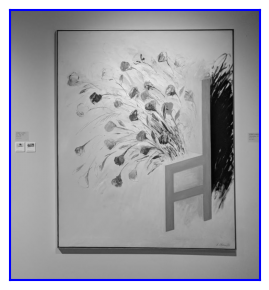

In [254]:
DATA_DIR = Path().resolve().parent / 'data'
BBDD_DIR = DATA_DIR / 'BBDD'
QSD2 = DATA_DIR / 'qsd2_w2'


IMG_ID = '00020'
CLOSE_FRACT = 0.06
OPEN_FRACT = 0.0673
MEDIAN_FRACT = 0.0190
BORDER_SIZE = 15
COLOR_SPACE = cv2.COLOR_BGR2HSV


img = cv2.cvtColor(cv2.imread(QSD2 / (IMG_ID + '.jpg')), cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
h, w = gray.shape

show(gray)

In [255]:
# img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.int16)
# H, S, V = cv2.split(img_hsv)

In [256]:
# v = 15
# border = np.zeros(gray.shape, bool)
# border[:v, :] = border[-v:, :] = border[:, :v] = border[:, -v:] = True

# wall_pixels = img_hsv[border]
# wall_mean = np.mean(wall_pixels, axis=0)

# weights = np.array([0, 0.226156, 0.648148])

# delta = img_hsv - wall_mean
# distance = np.sqrt(np.sum(weights * delta**2, axis=2))

# show(img, distance)

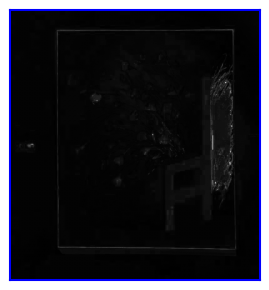

In [257]:
color = cv2.cvtColor(img, COLOR_SPACE).astype(np.float32)

height, width = color.shape[:2]

border = np.zeros((height, width), dtype=bool)
b = max(1, min(BORDER_SIZE, height // 2, width // 2))

border[:b, :] = True
border[-b:, :] = True
border[:, :b] = True
border[:, -b:] = True

# Estimate the background color distribution
background_pixels = color[border].astype(np.float64)
mean = background_pixels.mean(axis=0)

# Estimate covariance and regularize it for numerical stability
covariance = np.cov(background_pixels, rowvar=False)
covariance += np.eye(3) * 1e-3

inverse_covariance = np.linalg.pinv(covariance)

# Calculate the Mahalanobis distance for every pixel
delta = color.astype(np.float64) - mean

distance_squared = np.einsum(
    "...i,ij,...j->...",
    delta,
    inverse_covariance,
    delta,
)

distance = np.sqrt(np.maximum(distance_squared, 0)).astype(np.float32)

show(norm(distance))

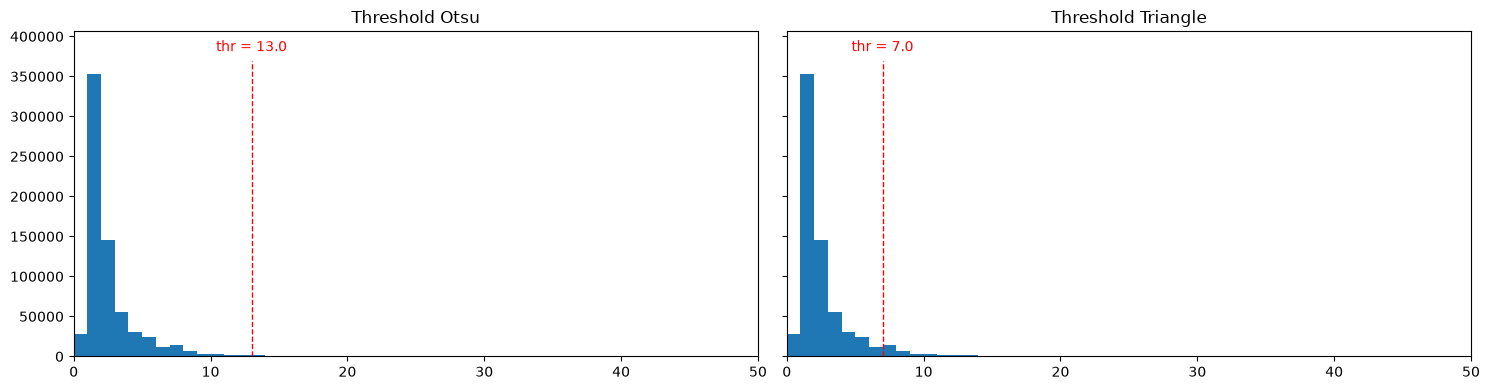

In [258]:
src = distance.astype(np.uint8)

hist, bins = np.histogram(src, bins=256, range=(0, 256))
thr1, bw = cv2.threshold(src, 0, 256, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
thr2, bw = cv2.threshold(src, 0, 256, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)

fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)

axs[0].bar((bins[1:] + bins[:-1]) / 2, hist, width=1)
axs[0].axvline(thr1, color='red', linestyle='--', linewidth=1, ymax=0.91)
axs[0].text(float(thr1), np.max(hist) * 1.08, f'thr = {thr1:.1f}', color='red', ha='center')
axs[0].set_ylim(0, np.max(hist) * 1.15)
axs[0].set_xlim(0, 50)
axs[0].set_title('Threshold Otsu')

axs[1].bar((bins[1:] + bins[:-1]) / 2, hist, width=1)
axs[1].axvline(thr2, color='red', linestyle='--', linewidth=1, ymax=0.91)
axs[1].text(float(thr2), np.max(hist) * 1.08, f'thr = {thr2:.1f}', color='red', ha='center')
axs[1].set_ylim(0, np.max(hist) * 1.15)
axs[1].set_xlim(0, 50)
axs[1].set_title('Threshold Triangle')

plt.tight_layout()
plt.show()

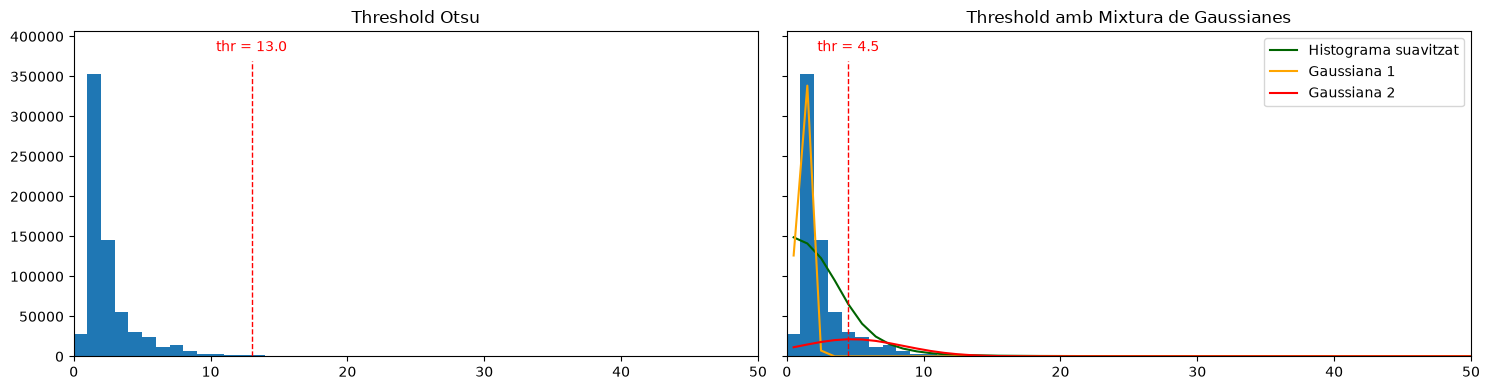

In [259]:
from sklearn.mixture import GaussianMixture
from scipy.ndimage import gaussian_filter1d

src = distance.astype(np.uint8)

# Otsu
hist, bins = np.histogram(src, bins=256, range=(0, 256))
thr1, bw = cv2.threshold(src, 0, 256, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Mixtura de Gaussianes
sample = cv2.resize(src, (14, 14), interpolation=cv2.INTER_CUBIC).reshape(-1, 1)
gmm = GaussianMixture(n_components=2, covariance_type='full')
gmm.fit(sample)
means = gmm.means_.flatten()
covs = gmm.covariances_.flatten()
weights = gmm.weights_.flatten()
m1, m2 = np.sort(means)

hist_smooth = gaussian_filter1d(hist, sigma=2)
bin_centers = (bins[:-1] + bins[1:]) / 2

mask = (bin_centers > m1) & (bin_centers < m2)
thr2 = bin_centers[mask][np.argmin(hist_smooth[mask])]

pdf1 = weights[0] * np.exp(-0.5 * ((bin_centers - means[0])**2) / covs[0]) / np.sqrt(2 * np.pi * covs[0])
pdf2 = weights[1] * np.exp(-0.5 * ((bin_centers - means[1])**2) / covs[1]) / np.sqrt(2 * np.pi * covs[1])
pdf_scale = np.max(hist) / np.max(pdf1 + pdf2)

# Gràfica
fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)

axs[0].bar((bins[1:] + bins[:-1]) / 2, hist, width=1)
axs[0].axvline(thr1, color='red', linestyle='--', linewidth=1, ymax=0.91)
axs[0].text(float(thr1), np.max(hist) * 1.08, f'thr = {thr1:.1f}', color='red', ha='center')
axs[0].set_ylim(0, np.max(hist) * 1.15)
axs[0].set_xlim(0, 50)
axs[0].set_title('Threshold Otsu')

axs[1].bar(bin_centers, hist, width=1)
axs[1].plot(bin_centers, hist_smooth, color='darkgreen', label='Histograma suavitzat')
axs[1].plot(bin_centers, pdf1 * pdf_scale, color='orange', label='Gaussiana 1')
axs[1].plot(bin_centers, pdf2 * pdf_scale, color='red', label='Gaussiana 2')
axs[1].axvline(thr2, color='red', linestyle='--', linewidth=1, ymax=0.91)
axs[1].text(float(thr2), np.max(hist) * 1.08, f'thr = {thr2:.1f}', color='red', ha='center')
axs[1].set_ylim(0, np.max(hist) * 1.15)
axs[1].set_xlim(0, 50)
axs[1].set_title('Threshold amb Mixtura de Gaussianes')
axs[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

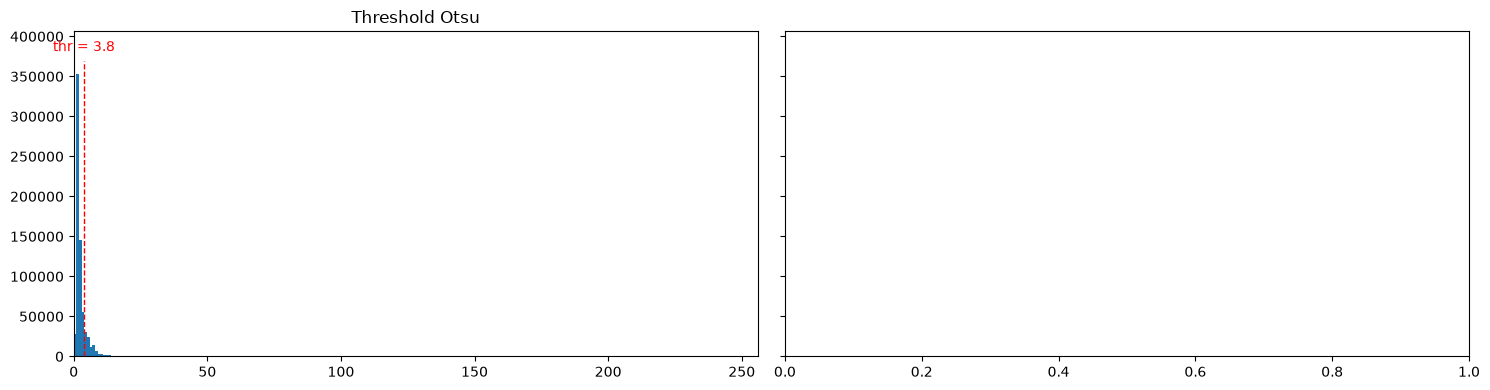

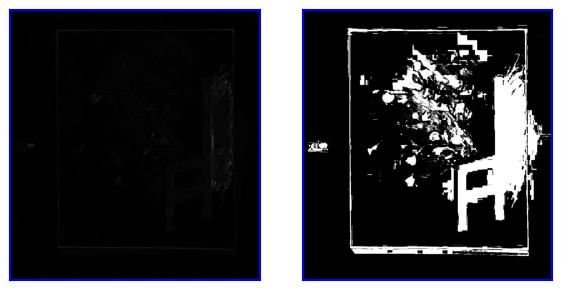

In [260]:
wall_d = distance[border].astype(np.float64)
t = np.median(wall_d) + 6 * 1.4826 * np.median(np.abs(wall_d - np.median(wall_d)))

hist, bins = np.histogram(src, bins=256, range=(0, 256))
fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)

axs[0].bar((bins[1:] + bins[:-1]) / 2, hist, width=1)
axs[0].axvline(t, color='red', linestyle='--', linewidth=1, ymax=0.91)
axs[0].text(float(t), np.max(hist) * 1.08, f'thr = {t:.1f}', color='red', ha='center')
axs[0].set_ylim(0, np.max(hist) * 1.15)
axs[0].set_xlim(0, 256)
axs[0].set_title('Threshold Otsu')

plt.tight_layout()
plt.show()

fg_raw = ((distance > t)*255).astype(np.uint8)

show(distance, fg_raw)

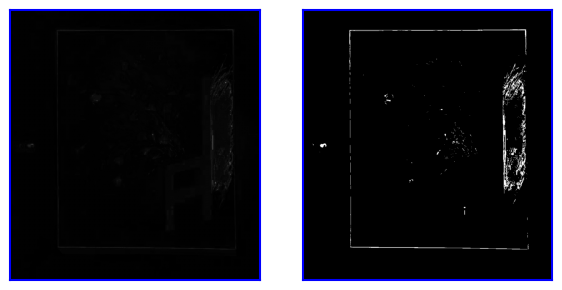

In [261]:
t, thr = cv2.threshold(distance.astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show(distance, thr)

In [262]:
# thr = cv2.medianBlur(thr, 5)

# show(thr)

thr = fg_raw

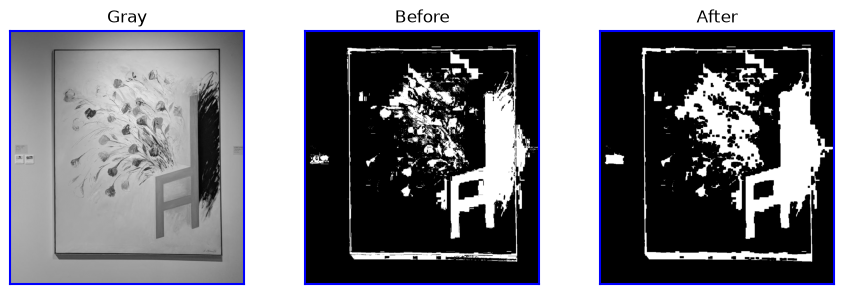

In [263]:
n = int(min(h,w)*0.01)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (n,n))

mask = cv2.morphologyEx(thr, cv2.MORPH_CLOSE, kernel)

show(gray, thr, mask, titles=['Gray', 'Before', 'After'])

In [ ]:
fg_raw = ndi.binary_fill_holes(labels == largest).astype(np.uint8)

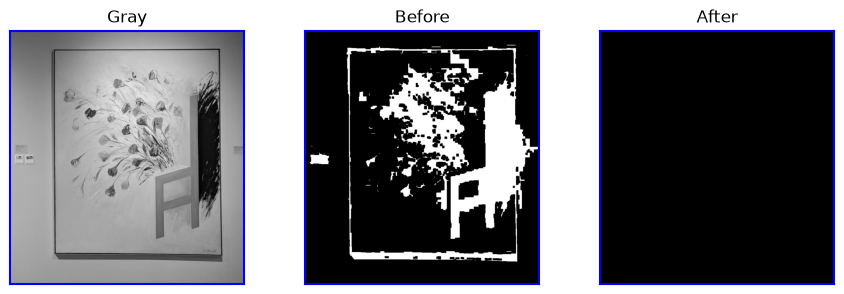

In [264]:
n = int(min(h,w)*0.2)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (n,n))

last = mask.copy()
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

show(gray, last, mask, titles=['Gray', 'Before', 'After'])

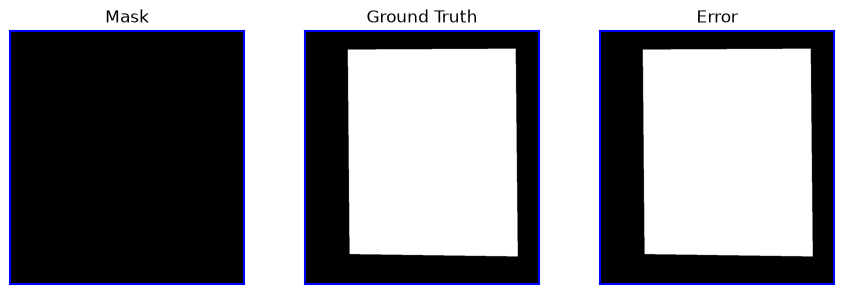

In [265]:
gt = cv2.imread(QSD2 / (IMG_ID+'.png'), cv2.IMREAD_GRAYSCALE)

err = cv2.absdiff(mask, gt)

show(mask, gt, err, titles=['Mask', 'Ground Truth', 'Error'])